# Yi-Ning Li
# DSCI552 HW 5

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.tree import _tree
from sklearn.impute import SimpleImputer
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

## 1. Decision Trees as Interpretable Models

### a. Download data

In [2]:
columns=['Temperature', 'Nausea', 'Lumbar_pain', 'Urine_pushing', 'Micturition_pains', 'Burning_urethra', 'Inflammation', 'Nephritis']

df=pd.read_csv('../data/diagnosis.data', header=None, sep=r'\s+', names=columns, decimal=',', encoding='utf-16')

print(df.shape)
display(df.head())

(120, 8)


,Temperature,Nausea,Lumbar_pain,Urine_pushing,Micturition_pains,Burning_urethra,Inflammation,Nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


### b. decision tree

X shape:  (120, 6)
y shape:  (120, 2)
Tree depth:  4
Numbe of leaves:  6


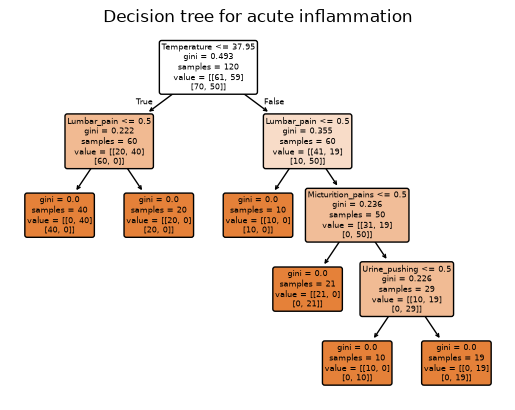

In [3]:
X=df.iloc[:, :6].replace({'yes': 1, 'no': 0}).astype(float)
y=df.iloc[:, 6:].replace({'yes': 1, 'no': 0}).astype(int)

print('X shape: ', X.shape)
print('y shape: ', y.shape)

tree=DecisionTreeClassifier(random_state=1)
tree.fit(X, y)

print('Tree depth: ', tree.get_depth())
print('Numbe of leaves: ', tree.get_n_leaves())

plt.figure()
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title('Decision tree for acute inflammation')
plt.show()

### c. If-then rules

In [4]:
def extractRules(model, featureNames, targetNames):
    t=model.tree_

    def traverse(node, conditions):
        if t.feature[node]==_tree.TREE_UNDEFINED:
            prediction=model.classes_
            values=t.value[node]

            outcomes={
                name: classes[values[i].argmax()]
                for i, (name, classes) in enumerate(zip(targetNames, prediction))
            }

            print('IF ' + ' AND '.join(conditions))
            print('THEN ' + ', '.join(f'{name}={value}' for name, value in outcomes.items()))
            print()
            return
        feature=featureNames[t.feature[node]]
        threshold=t.threshold[node]

        traverse(t.children_left[node], conditions + [f'{feature} <= {threshold:.2f}'])
        traverse(t.children_right[node], conditions + [f'{feature} > {threshold:.2f}'])
    traverse(0, [])
extractRules(tree, list(X.columns), list(y.columns))

IF Temperature <= 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=1, Nephritis=0

IF Temperature <= 37.95 AND Lumbar_pain > 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Micturition_pains <= 0.50
THEN Inflammation=0, Nephritis=1

IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Micturition_pains > 0.50 AND Urine_pushing <= 0.50
THEN Inflammation=0, Nephritis=1

IF Temperature > 37.95 AND Lumbar_pain > 0.50 AND Micturition_pains > 0.50 AND Urine_pushing > 0.50
THEN Inflammation=1, Nephritis=1



### d. cost-complexity pruning

In [5]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas
print('CCP alphas: ', alphas)

CCP alphas:  [0.         0.04908333 0.07947222 0.11111111 0.20423611]


In [6]:
results=[]

for alpha in alphas:
    prunedTree=DecisionTreeClassifier(random_state=1, ccp_alpha=alpha)
    prunedTree.fit(X, y)
    results.append({
        'alpha': alpha,
        'depth': prunedTree.get_depth(),
        'leaves': prunedTree.get_n_leaves(),
        'accuracy': prunedTree.score(X, y)
    })

resultsDF=pd.DataFrame(results)
display(resultsDF)

,alpha,depth,leaves,accuracy
0,0.000000,4,6,1.000000
1,0.049083,2,4,0.841667
2,0.079472,2,3,0.758333
3,0.111111,1,2,0.591667
4,0.204236,0,1,0.250000


Select alpha=0.049083 for its high accuracy and relatively fewer leaves. We are looking for a tree with fewer leaves and higher accuracy. Alpha=0 is the original tree without pruning. alpha=0.079472 has a lower accuracy of 0.758 despite having 1 less leaf. Alpha=0.111 and 0.204 have even lower accuracies despite having fewer leaves. 4 Leaves is still relatively small and easy to interpret, so we select alpha=0.049083 for its good interpretability and high accuracy. 

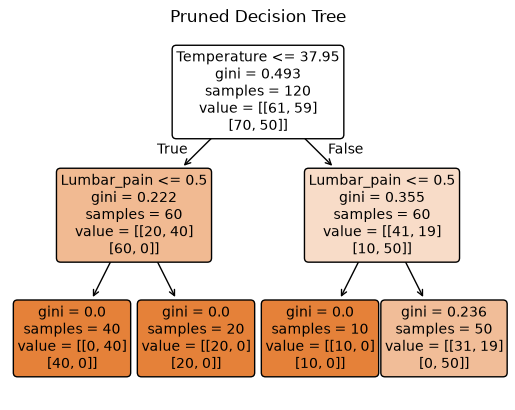

IF Temperature <= 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=1, Nephritis=0

IF Temperature <= 37.95 AND Lumbar_pain > 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain <= 0.50
THEN Inflammation=0, Nephritis=0

IF Temperature > 37.95 AND Lumbar_pain > 0.50
THEN Inflammation=0, Nephritis=1



In [7]:
bestAlpha=alphas[1]
prunedTree=DecisionTreeClassifier(random_state=1, ccp_alpha=bestAlpha)
prunedTree.fit(X, y)

plt.figure()
plot_tree(
    prunedTree,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Pruned Decision Tree')
plt.show()

extractRules(prunedTree, list(X.columns), list(y.columns))

## 2. The LASSO and Boosting for Regression

### a. download data

In [8]:
crimeDF=pd.read_csv('../data/communities.data', header=None, na_values='?')
print('Dataset shape: ', crimeDF.shape)
display(crimeDF.head())

Dataset shape:  (1994, 128)


,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [9]:
trainDF=crimeDF.iloc[:1495]
testDF=crimeDF.iloc[1495:]

print('Training shape: ', trainDF.shape)
print('Testing shape: ', testDF.shape)

Training shape:  (1495, 128)
Testing shape:  (499, 128)


### b. missing values

In [10]:
XTrain=trainDF.iloc[:, 5:127]
XTest=testDF.iloc[:, 5:127]
yTrain=trainDF.iloc[:, 127]
yTest=testDF.iloc[:, 127]

print('Training features: ', XTrain.shape)
print('Testing features: ', XTest.shape)

missing = XTrain.isna().sum()
print('Total missing values: ', missing.sum())
print('Features with missing values: ', (missing > 0).sum())
display(missing[missing > 0].sort_values(ascending=False))

Training features:  (1495, 122)
Testing features:  (499, 122)
Total missing values:  27633
Features with missing values:  23


101    1256
102    1256
103    1256
105    1256
104    1256
106    1256
107    1256
115    1256
108    1256
109    1256
110    1256
111    1256
112    1256
113    1256
114    1256
122    1256
116    1256
117    1256
121    1256
124    1256
123    1256
126    1256
30        1
dtype: int64

In [11]:
missingRatio=XTrain.isna().mean()
dropCols=missingRatio[missingRatio > 0.5].index

XTrain=XTrain.drop(columns=dropCols)
XTest=XTest.drop(columns=dropCols)

print('Dropped columns: ', len(dropCols))
print('Training shape: ', XTrain.shape)
print('Testing shape: ', XTest.shape)

Dropped columns:  22
Training shape:  (1495, 100)
Testing shape:  (499, 100)


In [12]:
imputer=SimpleImputer(strategy='median')

XTrain=pd.DataFrame(
    imputer.fit_transform(XTrain),
    columns=XTrain.columns,
    index=XTrain.index
)
XTest=pd.DataFrame(
    imputer.transform(XTest),
    columns=XTest.columns,
    index=XTest.index
)

print('Training missing values: ', XTrain.isna().sum().sum())
print('Testing missing values: ', XTest.isna().sum().sum())

Training missing values:  0
Testing missing values:  0


There are no missing values in both training and testing datasets. 

### c. correlation matrix

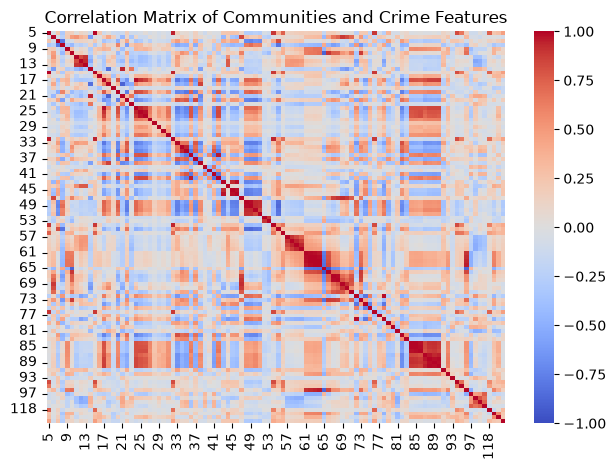

In [13]:
corrMatrix=XTrain.corr()

plt.figure()
sns.heatmap(
    corrMatrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix of Communities and Crime Features')
plt.tight_layout()
plt.show()

### d. CV

In [14]:
CV=XTrain.std(ddof=1)/XTrain.mean()
display(CV)

5      2.241105
6      0.355800
7      1.428885
8      0.330213
9      1.359100
         ...   
100    0.298434
118    1.645408
119    0.864499
120    1.397110
125    2.552946
Length: 100, dtype: float64

In [15]:
CVSorted=CV.sort_values(ascending=False)
display(CVSorted)

95     4.292923
94     3.470952
54     3.058964
56     2.926635
125    2.552946
         ...   
47     0.317375
100    0.298434
12     0.291315
65     0.289999
77     0.268182
Length: 100, dtype: float64

### e. highest CV plots

Selected features:  [95, 94, 54, 56, 125, 32, 5, 15, 76, 118, 10]


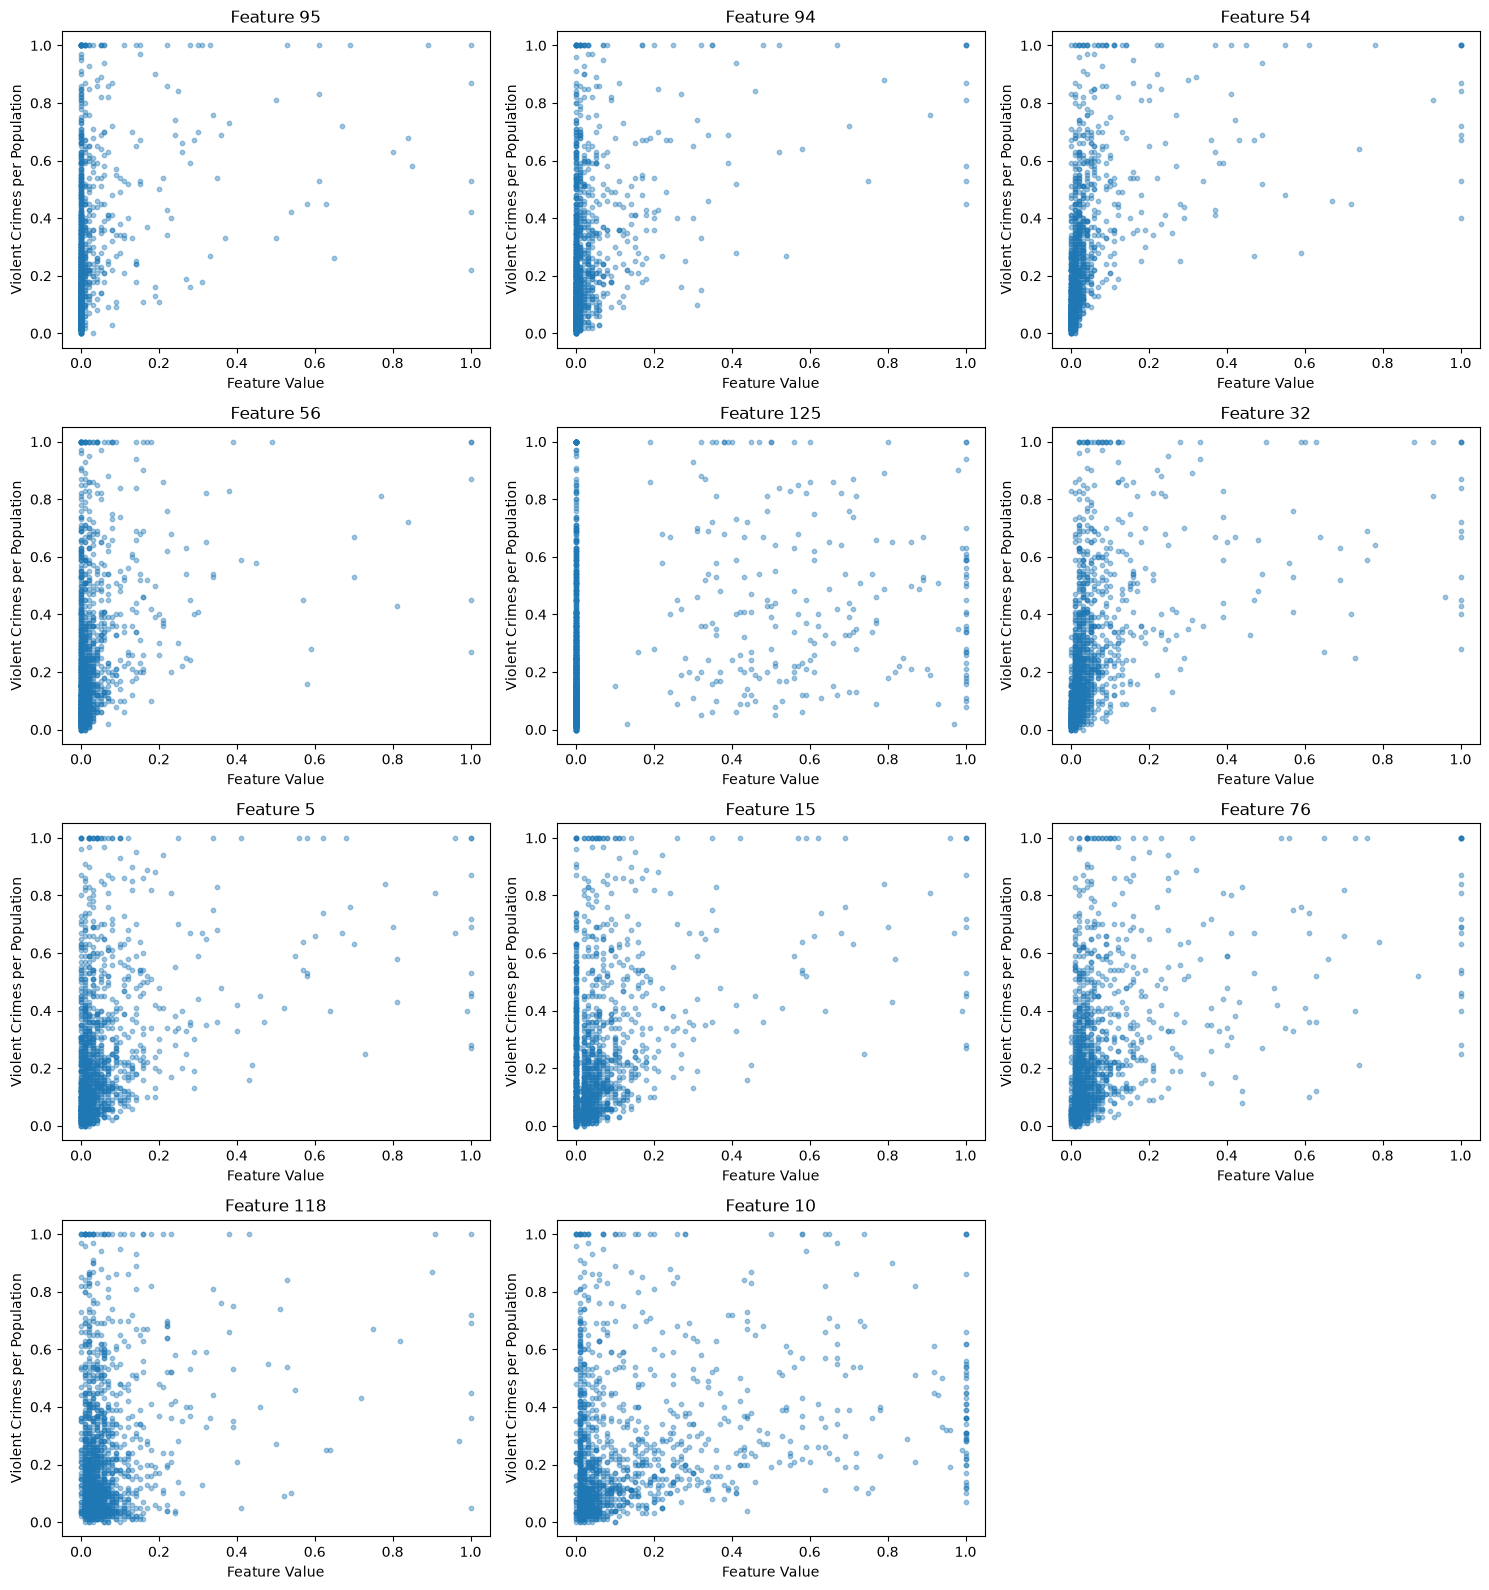

In [16]:
topFeatures=CVSorted.head(11).index
print('Selected features: ', topFeatures.tolist())

fig, axes=plt.subplots(4, 3, figsize=(15, 16))
axes=axes.flatten()

for i, feature in enumerate(topFeatures):
    axes[i].scatter(XTrain[feature], yTrain, alpha=0.4, s=10)
    axes[i].set_title(f'Feature {feature}')
    axes[i].set_xlabel('Feature Value')
    axes[i].set_ylabel('Violent Crimes per Population')

for ax in axes[len(topFeatures):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

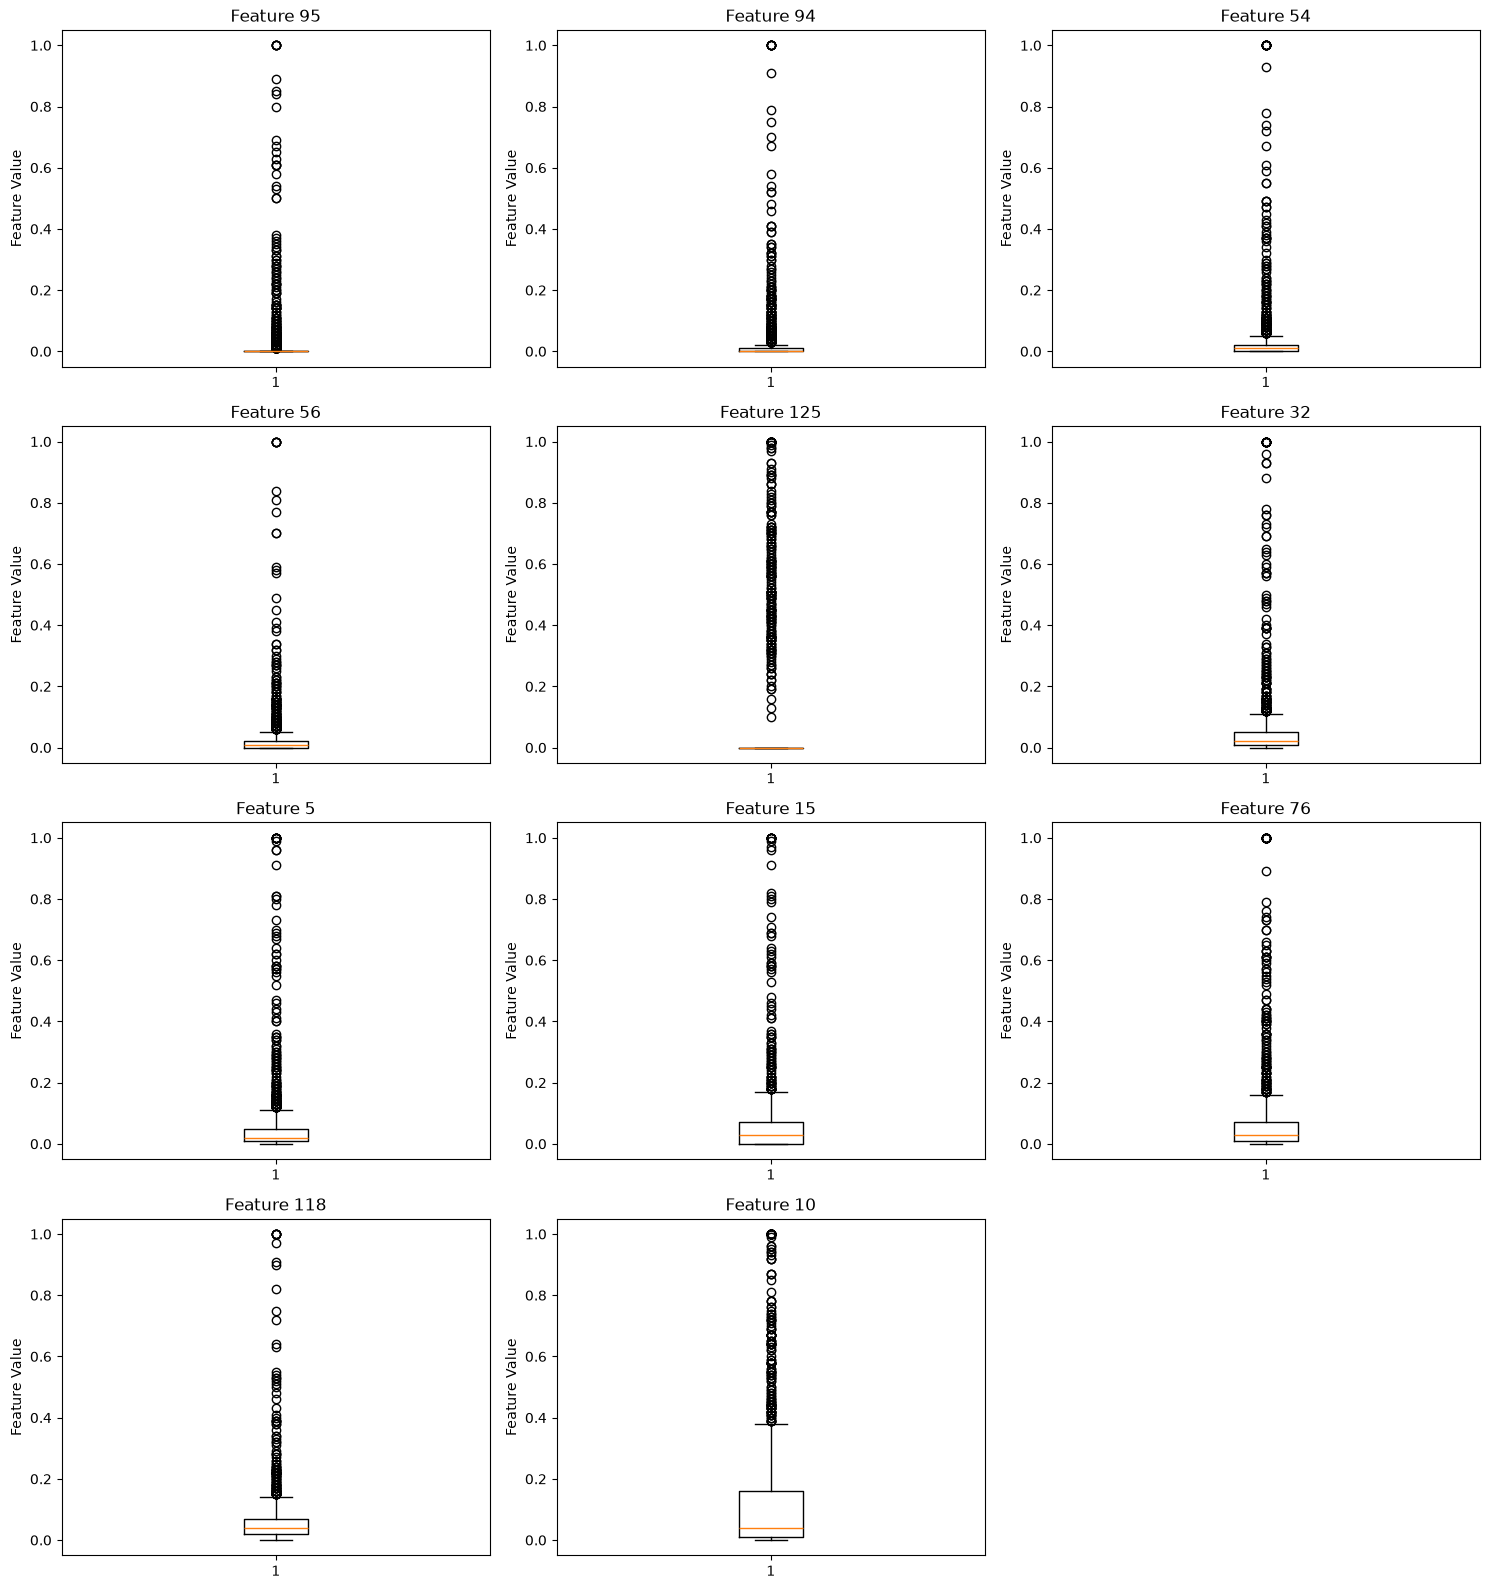

In [17]:
fig, axes=plt.subplots(4, 3, figsize=(15, 16))
axes=axes.flatten()

for i, feature in enumerate(topFeatures):
    axes[i].boxplot(XTrain[feature].dropna())
    axes[i].set_title(f'Feature {feature}')
    axes[i].set_ylabel('Feature Value')

for ax in axes[len(topFeatures):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

We cannot determine the statistical significance of the features only from the scatter plots. Most features have values concentrated near 0 with several outliers, and there are no strong linear relationships with the target variable. Even though the plots help visualize potential relationships and distributions, sstatistical significance requires further analysis like regression modeling and hypothesis testing. Also, a high CV indicates high relative variability, not its predictive performance. 

### f. linear model

In [18]:
linearModel=LinearRegression()
linearModel.fit(XTrain, yTrain)

yPred=linearModel.predict(XTest)
testMSE=mean_squared_error(yTest, yPred)

print('Linear Regression Test MSE: ', testMSE)

Linear Regression Test MSE:  0.017843929209456006


### g. ridge regression

In [19]:
ridgeAlphas=np.logspace(-4, 4, 100)
ridgeModel=RidgeCV(alphas=ridgeAlphas, cv=5)
ridgeModel.fit(XTrain, yTrain)

ridgePred=ridgeModel.predict(XTest)
ridgeMSE=mean_squared_error(yTest, ridgePred)

print('Best lambda: ', ridgeModel.alpha_)
print('Ridge Regression Test MSE: ', ridgeMSE)

Best lambda:  1.3219411484660315
Ridge Regression Test MSE:  0.017471673664427548


### h. LASSO regression

In [20]:
lassoModel=LassoCV(cv=5, random_state=1, max_iter=100000)
lassoModel.fit(XTrain, yTrain)
lassoPred=lassoModel.predict(XTest)
lassoMSE=mean_squared_error(yTest, lassoPred)
selectedFeatures=XTrain.columns[abs(lassoModel.coef_) > 1e-8]

print('Unstandardized LASSO Results')
print('Best lambda: ', lassoModel.alpha_)
print('LASSO Test MSE: ', lassoMSE)
print('Number of selected features: ', len(selectedFeatures))
print('Selected features: ', selectedFeatures.tolist())

Unstandardized LASSO Results
Best lambda:  0.00011614723626829846
LASSO Test MSE:  0.01756869294347602
Number of selected features:  67
Selected features:  [7, 9, 11, 12, 14, 15, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 58, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 118, 119, 120, 125]


In [21]:
scaler=StandardScaler()
XTrainScaled=scaler.fit_transform(XTrain)
XTestScaled=scaler.transform(XTest)

lassoScaled=LassoCV(cv=5, random_state=1, max_iter=100000)
lassoScaled.fit(XTrainScaled, yTrain)
scaledPred=lassoScaled.predict(XTestScaled)
scaledMSE=mean_squared_error(yTest, scaledPred)
scaledFeatures=XTrain.columns[abs(lassoScaled.coef_) > 1e-8]

print('Standardized LASSO Results')
print('Best lambda: ', lassoScaled.alpha_)
print('Standardized LASSO Test MSE: ', scaledMSE)
print('Number of selected features: ', len(scaledFeatures))
print('Selected features: ', scaledFeatures.tolist())

Standardized LASSO Results
Best lambda:  0.0006636910154760816
Standardized LASSO Test MSE:  0.017565200701817902
Number of selected features:  66
Selected features:  [5, 7, 9, 11, 12, 14, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 118, 119, 120, 125]


The unstandardized LASSO model had a test MSE of 0.017569 and selected 67 features, while the standardized LASSO model had a test MSE of 0.017565 and selected 66 features. Therefore, standardization slightly improved predictive performance with the smaller MSE, but the difference between the two MSEs is rather small, only 0.000004. This may be because the original dataset was already normalized, so additional standardization did not make a big difference. 

### i. PCR

In [22]:
pcr=Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('regression', LinearRegression())
])

params={'pca__n_components': list(range(1, 101))}
pcrCV=GridSearchCV(pcr, params, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
pcrCV.fit(XTrain, yTrain)

print('Best M: ', pcrCV.best_params_['pca__n_components'])

pcrPred=pcrCV.predict(XTest)
pcrMSE=mean_squared_error(yTest, pcrPred)

print('PCR Test MSE:', pcrMSE)

Best M:  77
PCR Test MSE: 0.01812953601905767


### j. XGBoost

In [23]:
xgb=XGBRegressor(
    objective='reg:squarederror',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=1,
    n_jobs=1
)
params={'reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10]}
xgbCV = GridSearchCV(
    xgb,
    params,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
xgbCV.fit(XTrain, yTrain)

print('Best alpha: ', xgbCV.best_params_['reg_alpha'])

xgbPred=xgbCV.predict(XTest)
xgbMSE=mean_squared_error(yTest, xgbPred)

print('XGBoost Test MSE: ', xgbMSE)

Best alpha:  0.001
XGBoost Test MSE:  0.016301876932052026
